# MoE Study Final Visualizations: 96 and 200 Languages

- loads final-result workbooks, vidualizes each langaues as a point in boxplots accorss approaches
- **Belebele, SIB200, and Taxi1500:** original scores, including the baseline as an approach.
- **FLORES en→x and x→en:** paired BPB improvement over the same-language baseline; positive is better.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "result_analysis/reports/moe_study").is_dir()
)
REPORT_DIR = ROOT / "result_analysis/reports/moe_study"
FIGURE_DIR = ROOT / "result_analysis/figures/final_top5_96_200_benchmarks"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

REPORTS = {
    "96 languages": REPORT_DIR / "moe_study_final_96_languages_2026-07-25.xlsx",
    "200 languages": REPORT_DIR / "moe_study_final_200_languages_2026-07-25.xlsx",
}
MANIFESTS = {
    "96 languages": ROOT / "result_analysis/l2v_nested_samples/96.csv",
    "200 languages": ROOT / "result_analysis/l2v_nested_samples/200.csv",
}

ENGLISH_LANGUAGE = "eng_Latn"
BASELINE = "baseline::l-3-1-8b"
FINAL_APPROACHES = [
    "moelora_tr32_e16_k8",
    "hydralora_r2",
    "moelora_tr64_e32_k8",
    "mola_tr16_e8_k6",
    "mtllora_lr5e5_r8_nup16",
]
ALL_RUNS = [BASELINE, *FINAL_APPROACHES]
EXPECTED_ROWS_PER_RUN = {"96 languages": 249, "200 languages": 408}
RESOURCE_GROUPS = ["HIGH", "MEDIUM", "LOW"]
RESOURCE_AVAILABILITY_OVERRIDES = {
    "azj_Latn": "MEDIUM",
    "lvs_Latn": "MEDIUM",
}


In [2]:
def load_panel(label):
    """Load primary benchmark scores for the CSV languages plus English."""
    manifest = pd.read_csv(MANIFESTS[label])
    trained_languages = set(
        manifest.loc[manifest["split"].eq("train"), "subset"].astype(str)
    )
    allowed_languages = trained_languages | {ENGLISH_LANGUAGE}

    raw = pd.read_excel(REPORTS[label], sheet_name="benchmark_raw")
    primary = (
        ((raw.benchmark == "Belebele") & (raw.metric == "acc_norm"))
        | ((raw.benchmark == "FLORES") & raw.metric.astype(str).str.startswith("bits_per_byte "))
        | ((raw.benchmark == "SIB200") & (raw.metric == "acc"))
        | ((raw.benchmark == "Taxi1500") & (raw.metric == "acc"))
    )
    data = raw.loc[primary & raw.language.astype(str).isin(allowed_languages)].copy()
    data["value"] = pd.to_numeric(data["value"], errors="coerce")
    data = data.dropna(subset=["value"])
    data["direction"] = data.metric.astype(str).str.extract(
        r"(en->x|x->en)", expand=False
    ).fillna("")
    data["score_family"] = np.where(
        data.benchmark.eq("FLORES"), "FLORES " + data.direction, data.benchmark
    )
    data["resource_availability"] = data.language.map(
        RESOURCE_AVAILABILITY_OVERRIDES
    ).fillna(data.resource_availability)

    assert set(data.run_id) == set(ALL_RUNS)
    assert data.groupby("run_id").size().eq(EXPECTED_ROWS_PER_RUN[label]).all()
    assert set(data.language.astype(str)) <= allowed_languages
    return data


panels = {label: load_panel(label) for label in REPORTS}
for label, data in panels.items():
    print(
        f"{label}: {data.groupby('run_id').size().iloc[0]} primary rows/run; "
        f"{data.language.nunique()} reported languages"
    )


96 languages: 249 primary rows/run; 80 reported languages
200 languages: 408 primary rows/run; 136 reported languages


In [3]:
# Shared visual style and grouped box/scatter helper
APPROACH_COLORS = {
    BASELINE: "#6B7280",
    "moelora_tr32_e16_k8": "#4C78A8",
    "hydralora_r2": "#E0B91E",
    "moelora_tr64_e32_k8": "#43B878",
    "mola_tr16_e8_k6": "#8B5CF6",
    "mtllora_lr5e5_r8_nup16": "#E45756",
}

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
})


def save_figure(fig, stem):
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{stem}.svg", bbox_inches="tight")


def legend_handles(run_ids):
    return [
        plt.Line2D(
            [0], [0], marker="o", linestyle="none",
            markerfacecolor=APPROACH_COLORS[run_id], markeredgecolor="white",
            markersize=7, label=run_id,
        )
        for run_id in run_ids
    ]


def draw_resource_groups(ax, frame, value_column, run_ids, offsets, box_width):
    centers = np.arange(len(RESOURCE_GROUPS))
    resource_sizes = frame.groupby("resource_availability").language.nunique()

    for resource_index, resource in enumerate(RESOURCE_GROUPS):
        resource_frame = frame[frame.resource_availability.eq(resource)]
        languages = sorted(resource_frame.language.astype(str).unique())
        jitter = np.linspace(-0.035, 0.035, len(languages)) if len(languages) > 1 else [0.0]
        language_jitter = dict(zip(languages, jitter))

        for approach_index, run_id in enumerate(run_ids):
            points = resource_frame[resource_frame.run_id.eq(run_id)].sort_values("language")
            if points.empty:
                continue
            position = centers[resource_index] + offsets[approach_index]
            color = APPROACH_COLORS[run_id]
            ax.boxplot(
                [points[value_column]], positions=[position], widths=box_width,
                patch_artist=True, showfliers=False, manage_ticks=False,
                boxprops={"facecolor": color, "edgecolor": color, "alpha": 0.22},
                medianprops={"color": color, "linewidth": 1.8},
                whiskerprops={"color": color, "alpha": 0.7},
                capprops={"color": color, "alpha": 0.7},
            )
            point_x = position + points.language.astype(str).map(language_jitter).to_numpy()
            ax.scatter(
                point_x, points[value_column], s=18, color=color,
                edgecolor="white", linewidth=0.3, alpha=0.75, zorder=3,
            )

    ax.set_xticks(
        centers,
        [f"{resource}\n(n={int(resource_sizes.get(resource, 0))})" for resource in RESOURCE_GROUPS],
    )
    ax.set_xlabel("Language resource availability")
    ax.grid(axis="y", linestyle="--", alpha=0.3)


## SIB / BELEBEL / TAXI visualizations
- here we treat baselin also as one approach and visualize the top5 approaches for 96 / 200 languages



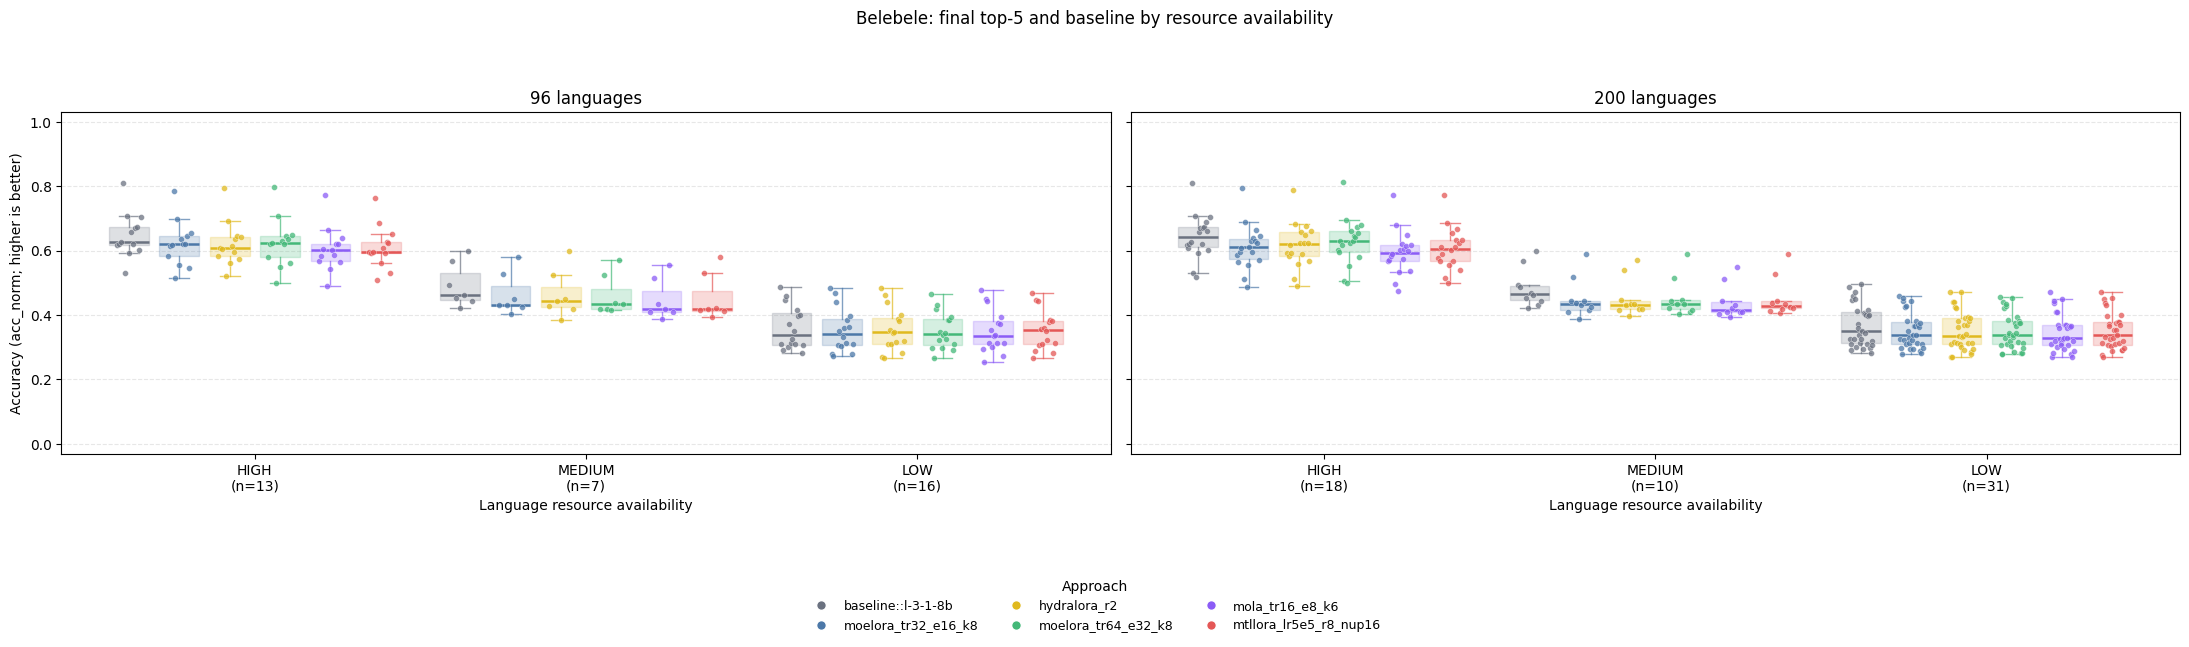

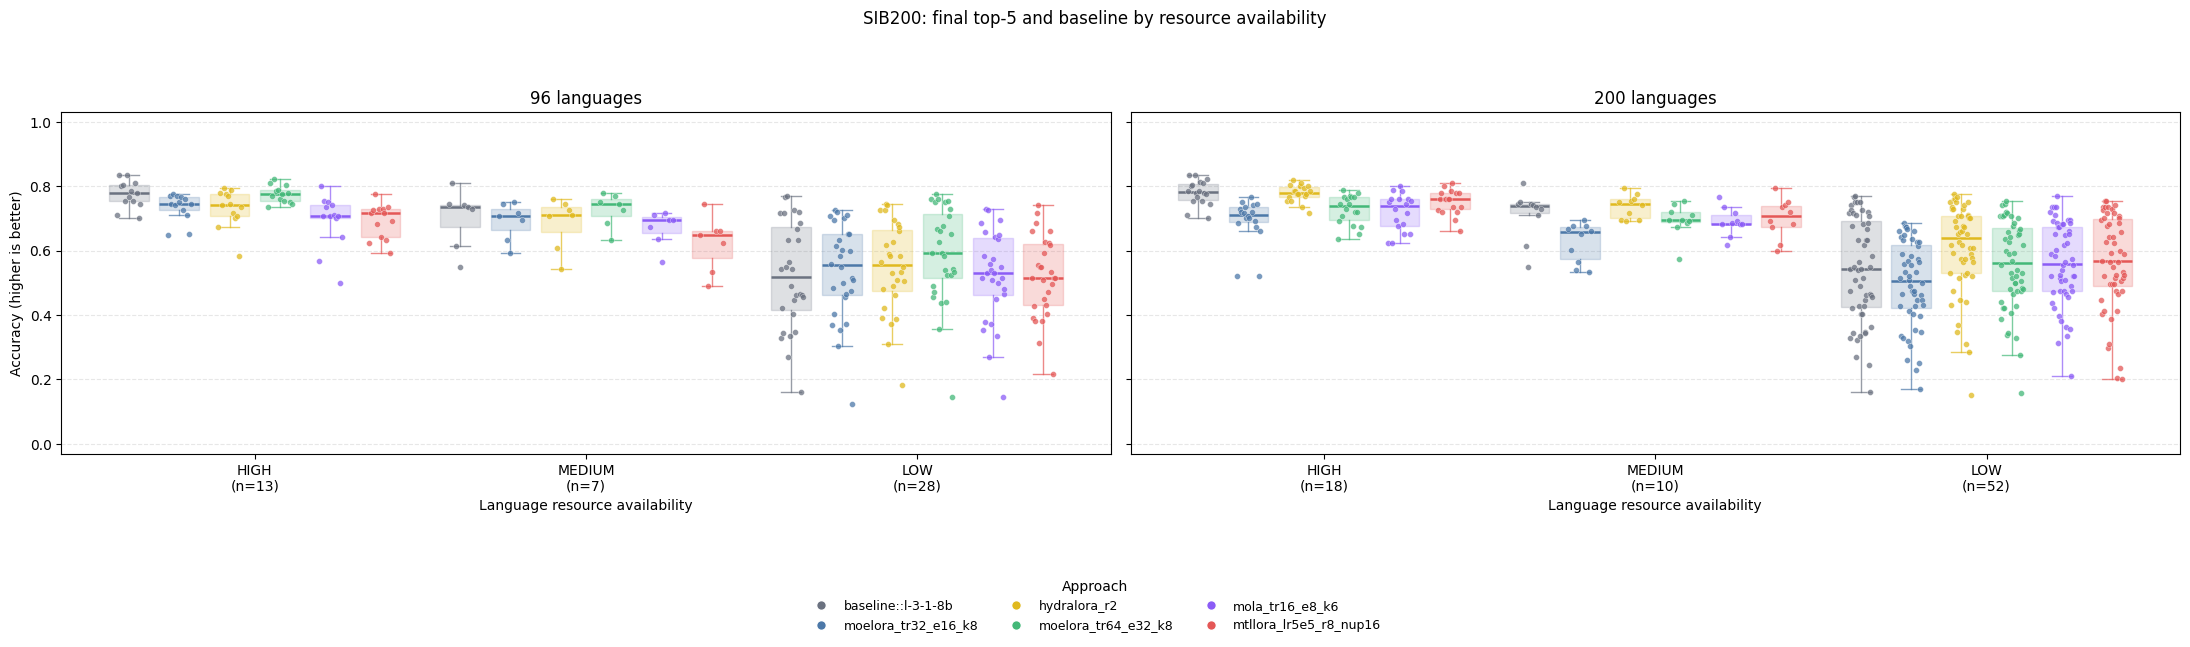

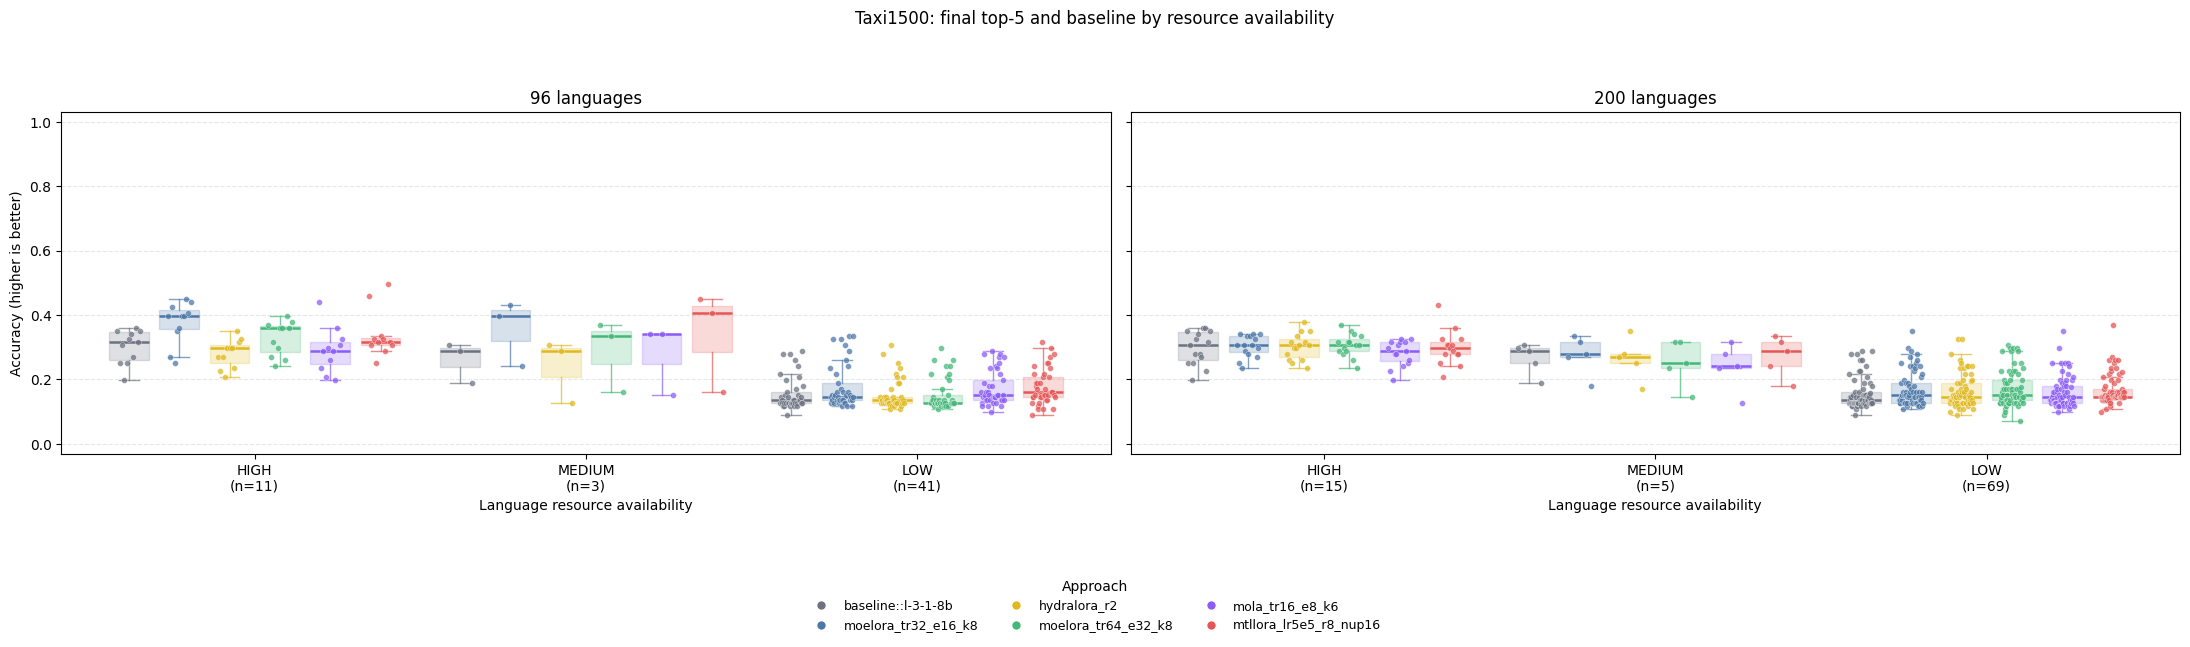

In [4]:
ORIGINAL_SCORE_FAMILIES = ["Belebele", "SIB200", "Taxi1500"]
SCORE_LABELS = {
    "Belebele": "Accuracy (acc_norm; higher is better)",
    "SIB200": "Accuracy (higher is better)",
    "Taxi1500": "Accuracy (higher is better)",
}
all_offsets = np.linspace(-0.38, 0.38, len(ALL_RUNS))

for score_family in ORIGINAL_SCORE_FAMILIES:
    fig, axes = plt.subplots(1, 2, figsize=(22, 6.4), sharey=True)

    for ax, (label, data) in zip(axes, panels.items()):
        family = data[
            data.score_family.eq(score_family)
            & data.resource_availability.isin(RESOURCE_GROUPS)
        ].copy()
        if set(family.run_id.unique()) != set(ALL_RUNS):
            raise ValueError(f"{label} / {score_family}: incomplete run coverage")

        draw_resource_groups(ax, family, "value", ALL_RUNS, all_offsets, box_width=0.12)
        ax.set_title(label)
        ax.set_ylim(-0.03, 1.03)

    axes[0].set_ylabel(SCORE_LABELS[score_family])
    fig.suptitle(f"{score_family}: final top-5 and baseline by resource availability", y=0.99)
    fig.legend(
        handles=legend_handles(ALL_RUNS), title="Approach",
        loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False,
    )
    fig.tight_layout(rect=(0, 0.18, 1, 0.94))
    save_figure(fig, f"resource_availability_{score_family.lower()}")
    plt.show()


## for FLORES, we show improvement relative to baseline

For every language and direction we show `improvement = baseline BPB − approach BPB`

Positive values therefore mean that the trained approach improves over the paired baseline.


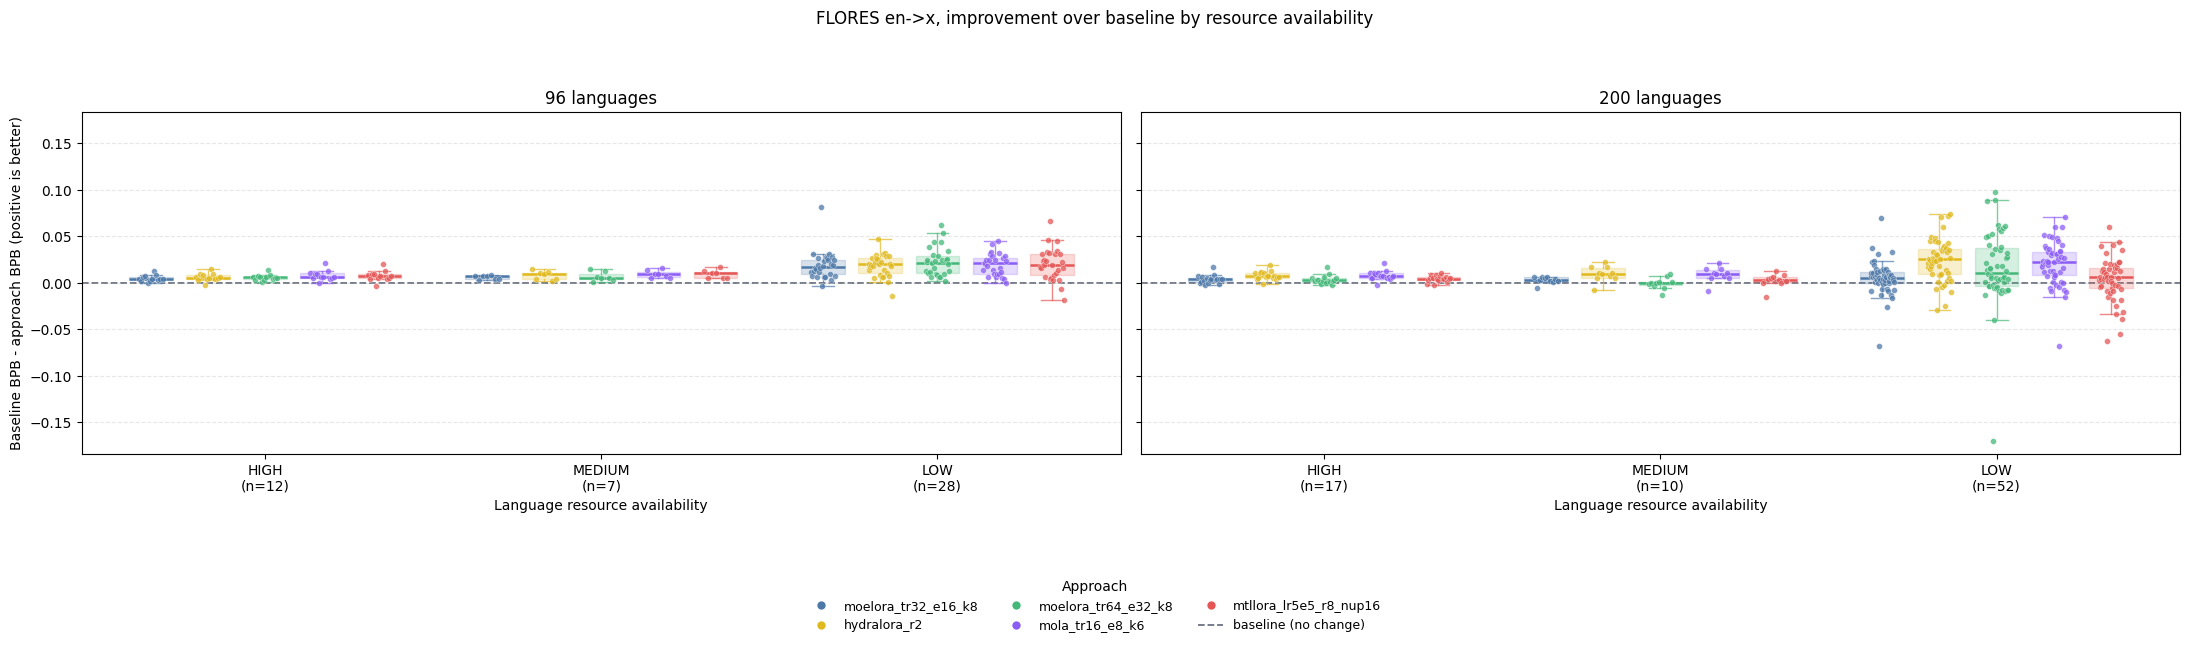

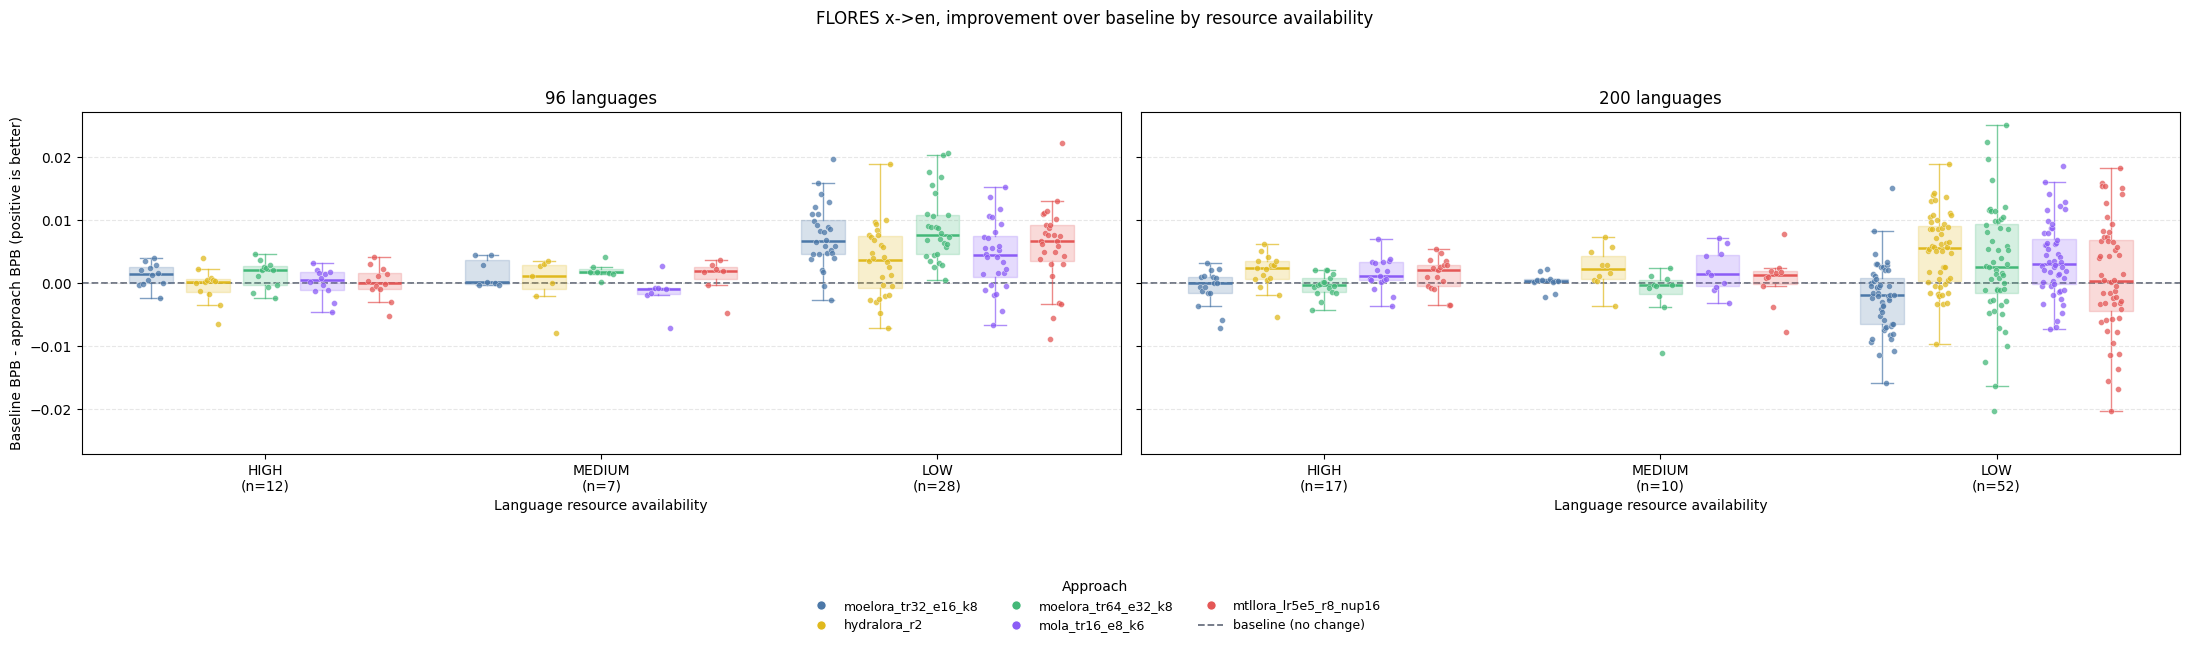

In [5]:
effect_offsets = np.linspace(-0.34, 0.34, len(FINAL_APPROACHES))
effect_handles = legend_handles(FINAL_APPROACHES) + [
    plt.Line2D(
        [0], [0], color=APPROACH_COLORS[BASELINE], linestyle="--",
        linewidth=1.3, label="baseline (no change)",
    )
]

for direction in ["en->x", "x->en"]:
    effects_by_panel = {}
    for label, data in panels.items():
        flores = data[
            data.score_family.eq(f"FLORES {direction}")
            & data.resource_availability.isin(RESOURCE_GROUPS)
        ].copy()
        wide = flores.pivot(
            index=["resource_availability", "language"],
            columns="run_id", values="value",
        )
        missing = [run_id for run_id in ALL_RUNS if run_id not in wide.columns]
        if missing:
            raise ValueError(f"{label} / FLORES {direction}: missing {missing}")
        paired = wide.dropna(subset=ALL_RUNS)
        improvements = paired[FINAL_APPROACHES].rsub(paired[BASELINE], axis=0)
        effects = improvements.reset_index().melt(
            id_vars=["resource_availability", "language"],
            var_name="run_id", value_name="delta_bpb",
        )
        effects_by_panel[label] = effects

    max_abs = max(frame.delta_bpb.abs().max() for frame in effects_by_panel.values())
    y_limit = max(0.001, 1.08 * max_abs)
    fig, axes = plt.subplots(1, 2, figsize=(22, 6.4), sharey=True)

    for ax, (label, effects) in zip(axes, effects_by_panel.items()):
        ax.axhline(
            0, color=APPROACH_COLORS[BASELINE], linestyle="--",
            linewidth=1.3, zorder=1,
        )
        draw_resource_groups(
            ax, effects, "delta_bpb", FINAL_APPROACHES,
            effect_offsets, box_width=0.13,
        )
        ax.set_title(label)
        ax.set_ylim(-y_limit, y_limit)

    axes[0].set_ylabel("Baseline BPB - approach BPB (positive is better)")
    fig.suptitle(
        f"FLORES {direction}, improvement over baseline by resource availability",
        y=0.99,
    )
    fig.legend(
        handles=effect_handles, title="Approach",
        loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False,
    )
    fig.tight_layout(rect=(0, 0.18, 1, 0.94))
    direction_slug = direction.replace("->", "_to_")
    save_figure(fig, f"flores_{direction_slug}_improvement_over_baseline")
    plt.show()
